In [1]:
%pip install -q ultralytics --no-deps
%pip install -q ultralytics-thop --no-deps

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 46.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import gc
import shutil
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from PIL import Image
from tqdm import tqdm

from ultralytics import YOLO

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
import joblib

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [4]:
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")

print("Folders inside /kaggle/input:")
for p in INPUT_ROOT.iterdir():
    print(p)

Folders inside /kaggle/input:
/kaggle/input/datasets


In [5]:
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")

possible_data_dirs = []

for p in INPUT_ROOT.rglob("*"):
    if p.is_dir():
        if (p / "train").exists() and (p / "val").exists() and (p / "test").exists():
            possible_data_dirs.append(p)

print("Found possible dataset folders:")

for i, p in enumerate(possible_data_dirs):
    print(i, p)

DATASET_DIR = possible_data_dirs[0]

print("\nUsing DATASET_DIR:", DATASET_DIR)
print("Train exists:", (DATASET_DIR / "train").exists())
print("Val exists:", (DATASET_DIR / "val").exists())
print("Test exists:", (DATASET_DIR / "test").exists())

Found possible dataset folders:
0 /kaggle/input/datasets/ruhulamiinn/dumpalert-data-v3/data

Using DATASET_DIR: /kaggle/input/datasets/ruhulamiinn/dumpalert-data-v3/data
Train exists: True
Val exists: True
Test exists: True


In [6]:
from pathlib import Path

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def get_images(folder):
    folder = Path(folder)
    if not folder.exists():
        return []
    return [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMG_EXTS
    ]

print("\n=== Dataset Count ===")

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")
    for cls in ["Positive", "Negative"]:
        folder = DATASET_DIR / split / cls
        imgs = get_images(folder)
        print(f"{cls:<10} images: {len(imgs)}")


=== Dataset Count ===

TRAIN
Positive   images: 1368
Negative   images: 2004

VAL
Positive   images: 390
Negative   images: 564

TEST
Positive   images: 198
Negative   images: 300


In [8]:
MODEL_SIZE = "yolov8x-cls.pt"

EPOCHS = 30
IMG_SIZE = 224
PATIENCE = 10

if torch.cuda.device_count() >= 2:
    DEVICE = "0,1"
    BATCH_SIZE = 64
else:
    DEVICE = 0
    BATCH_SIZE = 32

RUN_NAME = "yolov8x_cls_dumpalert"

model = YOLO(MODEL_SIZE)

results = model.train(
    data=str(DATASET_DIR),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=4,

    project=str(OUTPUT_DIR),
    name=RUN_NAME,
    exist_ok=True,

    patience=PATIENCE,
    lr0=1e-3,
    lrf=0.01,

    augment=False,
    plots=True
)

YOLO_RUN_DIR = OUTPUT_DIR / RUN_NAME
YOLO_BEST_MODEL = YOLO_RUN_DIR / "weights" / "best.pt"
YOLO_FINAL_MODEL = OUTPUT_DIR / "yolov8x_cls_best.pt"

shutil.copy2(YOLO_BEST_MODEL, YOLO_FINAL_MODEL)

print("YOLO training complete.")
print("YOLO run dir:", YOLO_RUN_DIR)
print("Best model:", YOLO_BEST_MODEL)
print("Copied final model:", YOLO_FINAL_MODEL)
print("Best model exists:", YOLO_BEST_MODEL.exists())

Ultralytics 8.4.90 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                       CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/ruhulamiinn/dumpalert-data-v3/data, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8x-cls.pt, momentum=0.937, mosaic=1.0, multi

In [10]:
ML_OUTPUT_DIR = OUTPUT_DIR / "rf_svm_ann_models"
ML_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ML_IMG_SIZE = 64

# Label 0 = Negative/Clean
# Label 1 = Positive/Dump
CLASSES = ["Negative", "Positive"]
CLASS_DISPLAY = ["Clean", "Dump"]

def load_features(split):
    X = []
    y = []

    split_dir = DATASET_DIR / split

    for label, cls_name in enumerate(CLASSES):
        cls_dir = split_dir / cls_name
        image_paths = get_images(cls_dir)

        print(f"{split} - {cls_name}: {len(image_paths)} images")

        for img_path in tqdm(image_paths, desc=f"Loading {split} {cls_name}"):
            try:
                img = Image.open(img_path).convert("RGB")
                img = img.resize((ML_IMG_SIZE, ML_IMG_SIZE))

                arr = np.asarray(img, dtype=np.float32) / 255.0
                feature = arr.flatten()

                X.append(feature)
                y.append(label)

            except Exception as e:
                print("Skipped:", img_path, e)

    return np.array(X), np.array(y)


X_train, y_train = load_features("train")
X_val, y_val = load_features("val")
X_test, y_test = load_features("test")

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

train - Negative: 2004 images


Loading train Negative: 100%|██████████| 2004/2004 [07:55<00:00,  4.22it/s]


train - Positive: 1368 images


Loading train Positive: 100%|██████████| 1368/1368 [03:47<00:00,  6.00it/s]


val - Negative: 564 images


...

test - Negative: 300 images


Loading test Negative: 100%|██████████| 300/300 [01:09<00:00,  4.34it/s]


test - Positive: 198 images


Loading test Positive: 100%|██████████| 198/198 [00:34<00:00,  5.81it/s]

X_train: (3372, 12288)
X_val: (954, 12288)
X_test: (498, 12288)


In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

joblib.dump(scaler, ML_OUTPUT_DIR / "scaler.joblib")

print("Scaler saved:", ML_OUTPUT_DIR / "scaler.joblib")

Scaler saved: /kaggle/working/output/rf_svm_ann_models/scaler.joblib


In [12]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

rf_train_acc = accuracy_score(y_train, rf_model.predict(X_train))
rf_val_acc = accuracy_score(y_val, rf_model.predict(X_val))
rf_test_acc = accuracy_score(y_test, rf_model.predict(X_test))

print(f"RF Train Accuracy: {rf_train_acc:.4f}")
print(f"RF Val Accuracy:   {rf_val_acc:.4f}")
print(f"RF Test Accuracy:  {rf_test_acc:.4f}")

print("\nRF Validation Report:")
print(classification_report(y_val, rf_model.predict(X_val), target_names=CLASS_DISPLAY))

print("\nRF Test Report:")
print(classification_report(y_test, rf_model.predict(X_test), target_names=CLASS_DISPLAY))

joblib.dump(rf_model, ML_OUTPUT_DIR / "random_forest_model.joblib")
print("Random Forest saved:", ML_OUTPUT_DIR / "random_forest_model.joblib")

RF Train Accuracy: 1.0000
RF Val Accuracy:   0.8491
RF Test Accuracy:  0.8735

RF Validation Report:
              precision    recall  f1-score   support

       Clean       0.86      0.89      0.87       564
        Dump       0.83      0.79      0.81       390

    accuracy                           0.85       954
   macro avg       0.85      0.84      0.84       954
weighted avg       0.85      0.85      0.85       954


RF Test Report:
              precision    recall  f1-score   support

       Clean       0.89      0.90      0.90       300
        Dump       0.85      0.83      0.84       198

    accuracy                           0.87       498
   macro avg       0.87      0.87      0.87       498
weighted avg       0.87      0.87      0.87       498

Random Forest saved: /kaggle/working/output/rf_svm_ann_models/random_forest_model.joblib


In [13]:
svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    probability=True,
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

svm_train_acc = accuracy_score(y_train, svm_model.predict(X_train_scaled))
svm_val_acc = accuracy_score(y_val, svm_model.predict(X_val_scaled))
svm_test_acc = accuracy_score(y_test, svm_model.predict(X_test_scaled))

print(f"SVM Train Accuracy: {svm_train_acc:.4f}")
print(f"SVM Val Accuracy:   {svm_val_acc:.4f}")
print(f"SVM Test Accuracy:  {svm_test_acc:.4f}")

print("\nSVM Validation Report:")
print(classification_report(y_val, svm_model.predict(X_val_scaled), target_names=CLASS_DISPLAY))

print("\nSVM Test Report:")
print(classification_report(y_test, svm_model.predict(X_test_scaled), target_names=CLASS_DISPLAY))

joblib.dump(svm_model, ML_OUTPUT_DIR / "svm_model.joblib")
print("SVM saved:", ML_OUTPUT_DIR / "svm_model.joblib")

SVM Train Accuracy: 0.9997
SVM Val Accuracy:   0.8354
SVM Test Accuracy:  0.8193

SVM Validation Report:
              precision    recall  f1-score   support

       Clean       0.81      0.93      0.87       564
        Dump       0.88      0.69      0.77       390

    accuracy                           0.84       954
   macro avg       0.85      0.81      0.82       954
weighted avg       0.84      0.84      0.83       954


SVM Test Report:
              precision    recall  f1-score   support

       Clean       0.84      0.87      0.85       300
        Dump       0.79      0.74      0.77       198

    accuracy                           0.82       498
   macro avg       0.81      0.81      0.81       498
weighted avg       0.82      0.82      0.82       498

SVM saved: /kaggle/working/output/rf_svm_ann_models/svm_model.joblib


In [14]:
ann_model = MLPClassifier(
    hidden_layer_sizes=(512, 256, 128),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=1,
    warm_start=True,
    early_stopping=False,
    random_state=42,
    verbose=False
)

best_val_acc = 0
patience = 20
no_improve = 0
best_weights = None

ann_history = []

for epoch in range(100):
    ann_model.fit(X_train_scaled, y_train)

    train_acc = accuracy_score(y_train, ann_model.predict(X_train_scaled))
    val_acc = accuracy_score(y_val, ann_model.predict(X_val_scaled))

    ann_history.append({
        "Epoch": epoch + 1,
        "Train Accuracy": train_acc,
        "Validation Accuracy": val_acc
    })

    print(f"Epoch {epoch+1:3d}: train={train_acc:.4f}  val={val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        no_improve = 0
        best_weights = (
            [l.copy() for l in ann_model.coefs_],
            [l.copy() for l in ann_model.intercepts_]
        )
    else:
        no_improve += 1
        if no_improve >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

# Restore best weights
ann_model.coefs_ = best_weights[0]
ann_model.intercepts_ = best_weights[1]

ann_train_acc = accuracy_score(y_train, ann_model.predict(X_train_scaled))
ann_val_acc = accuracy_score(y_val, ann_model.predict(X_val_scaled))
ann_test_acc = accuracy_score(y_test, ann_model.predict(X_test_scaled))

print(f"Best ANN Val Accuracy: {best_val_acc:.4f}")
print(f"ANN Train Accuracy:    {ann_train_acc:.4f}")
print(f"ANN Val Accuracy:      {ann_val_acc:.4f}")
print(f"ANN Test Accuracy:     {ann_test_acc:.4f}")

print("\nANN Test Report:")
print(classification_report(y_test, ann_model.predict(X_test_scaled), target_names=CLASS_DISPLAY))

joblib.dump(ann_model, ML_OUTPUT_DIR / "ann_model.joblib")

pd.DataFrame(ann_history).to_csv(
    ML_OUTPUT_DIR / "ann_training_history.csv",
    index=False
)

print("ANN saved:", ML_OUTPUT_DIR / "ann_model.joblib")

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(


Epoch   1: train=0.7782  val=0.7170


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(


Epoch   2: train=0.8431  val=0.7275


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(


...

Epoch  42: train=0.9647  val=0.7715


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(


Epoch  43: train=0.9846  val=0.7652


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(


Epoch  44: train=0.9792  val=0.7568
Early stopping at epoch 44
Best ANN Val Accuracy: 0.7820
ANN Train Accuracy:    0.9769
ANN Val Accuracy:      0.7820
ANN Test Accuracy:     0.7510

ANN Test Report:
              precision    recall  f1-score   support

       Clean       0.78      0.82      0.80       300
        Dump       0.70      0.65      0.68       198

    accuracy                           0.75       498
   macro avg       0.74      0.73      0.74       498
weighted avg       0.75      0.75      0.75       498

ANN saved: /kaggle/working/output/rf_svm_ann_models/ann_model.joblib


In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

CM_DIR = OUTPUT_DIR / "confusion_matrices"
CM_DIR.mkdir(parents=True, exist_ok=True)

# Same label order used in ML models
CLASS_NAMES = ["Negative", "Positive"]
CLASS_TO_ID = {
    "Negative": 0,
    "Positive": 1
}

In [19]:
def save_confusion_matrix(y_true, y_pred, model_name, class_names=CLASS_NAMES):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    
    print(f"\n===== {model_name} =====")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))
    print("\nConfusion Matrix:")
    print(cm)
    
    # Save CSV
    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual_{c}" for c in class_names],
        columns=[f"Predicted_{c}" for c in class_names]
    )
    
    csv_path = CM_DIR / f"{model_name}_confusion_matrix.csv"
    cm_df.to_csv(csv_path)
    
    # Save image
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )
    
    fig, ax = plt.subplots(figsize=(6, 5))
    disp.plot(ax=ax, cmap="Blues", values_format="d")
    plt.title(f"{model_name} Confusion Matrix")
    
    img_path = CM_DIR / f"{model_name}_confusion_matrix.png"
    plt.savefig(img_path, dpi=300, bbox_inches="tight")
    plt.show()
    
    print("Saved CSV:", csv_path)
    print("Saved Image:", img_path)
    
    return cm

Total YOLO test images: 498

===== YOLOv8x_cls =====
Accuracy: 0.9678714859437751

Classification Report:
              precision    recall  f1-score   support

    Negative       0.96      0.99      0.97       300
    Positive       0.98      0.94      0.96       198

    accuracy                           0.97       498
   macro avg       0.97      0.96      0.97       498
weighted avg       0.97      0.97      0.97       498


Confusion Matrix:
[[296   4]
 [ 12 186]]


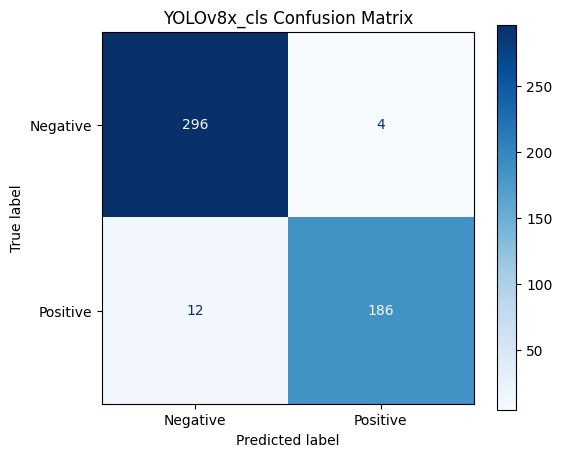

Saved CSV: /kaggle/working/output/confusion_matrices/YOLOv8x_cls_confusion_matrix.csv
Saved Image: /kaggle/working/output/confusion_matrices/YOLOv8x_cls_confusion_matrix.png


In [20]:
from ultralytics import YOLO

best_model = YOLO(str(YOLO_BEST_MODEL))

test_paths = []
y_true_yolo = []

for cls_name in CLASS_NAMES:
    cls_dir = DATASET_DIR / "test" / cls_name
    imgs = get_images(cls_dir)
    
    for img in imgs:
        test_paths.append(img)
        y_true_yolo.append(CLASS_TO_ID[cls_name])

print("Total YOLO test images:", len(test_paths))

y_pred_yolo = []

for img_path in test_paths:
    result = best_model.predict(
        source=str(img_path),
        imgsz=IMG_SIZE,
        device=DEVICE,
        verbose=False
    )[0]
    
    pred_index = int(result.probs.top1)
    pred_name = result.names[pred_index]
    
    # Convert YOLO predicted class name to our label id
    y_pred_yolo.append(CLASS_TO_ID[pred_name])

y_true_yolo = np.array(y_true_yolo)
y_pred_yolo = np.array(y_pred_yolo)

cm_yolo = save_confusion_matrix(
    y_true_yolo,
    y_pred_yolo,
    "YOLOv8x_cls"
)


===== Random_Forest =====
Accuracy: 0.8734939759036144

Classification Report:
              precision    recall  f1-score   support

    Negative       0.89      0.90      0.90       300
    Positive       0.85      0.83      0.84       198

    accuracy                           0.87       498
   macro avg       0.87      0.87      0.87       498
weighted avg       0.87      0.87      0.87       498


Confusion Matrix:
[[270  30]
 [ 33 165]]


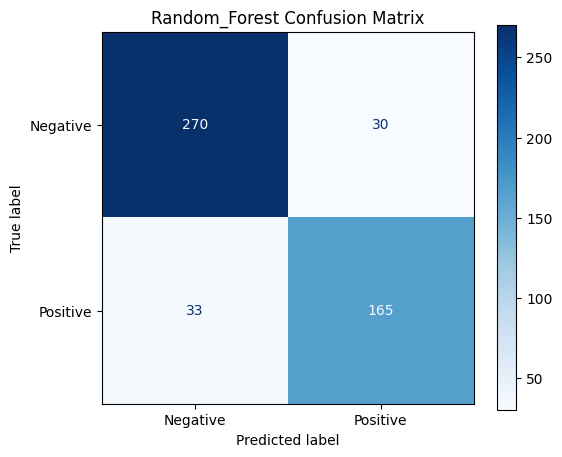

Saved CSV: /kaggle/working/output/confusion_matrices/Random_Forest_confusion_matrix.csv
Saved Image: /kaggle/working/output/confusion_matrices/Random_Forest_confusion_matrix.png


In [21]:
y_pred_rf = rf_model.predict(X_test)

cm_rf = save_confusion_matrix(
    y_test,
    y_pred_rf,
    "Random_Forest"
)


===== SVM =====
Accuracy: 0.8192771084337349

Classification Report:
              precision    recall  f1-score   support

    Negative       0.84      0.87      0.85       300
    Positive       0.79      0.74      0.77       198

    accuracy                           0.82       498
   macro avg       0.81      0.81      0.81       498
weighted avg       0.82      0.82      0.82       498


Confusion Matrix:
[[261  39]
 [ 51 147]]


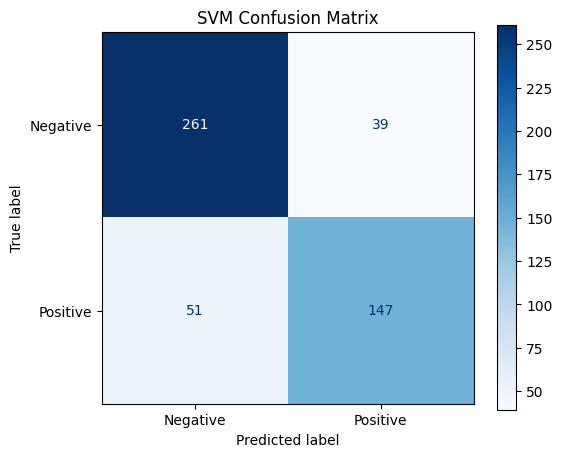

Saved CSV: /kaggle/working/output/confusion_matrices/SVM_confusion_matrix.csv
Saved Image: /kaggle/working/output/confusion_matrices/SVM_confusion_matrix.png


In [22]:
y_pred_svm = svm_model.predict(X_test_scaled)

cm_svm = save_confusion_matrix(
    y_test,
    y_pred_svm,
    "SVM"
)


===== ANN =====
Accuracy: 0.751004016064257

Classification Report:
              precision    recall  f1-score   support

    Negative       0.78      0.82      0.80       300
    Positive       0.70      0.65      0.68       198

    accuracy                           0.75       498
   macro avg       0.74      0.73      0.74       498
weighted avg       0.75      0.75      0.75       498


Confusion Matrix:
[[245  55]
 [ 69 129]]


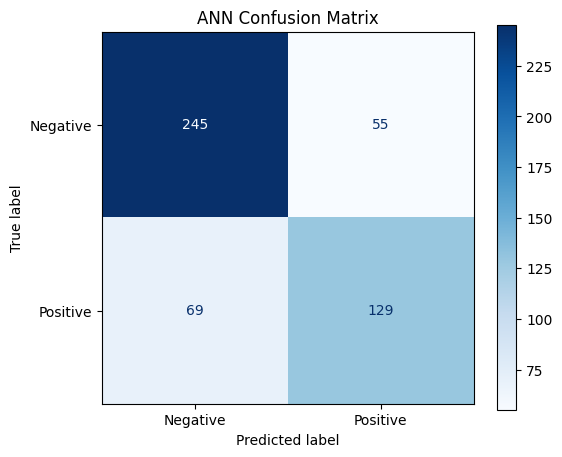

Saved CSV: /kaggle/working/output/confusion_matrices/ANN_confusion_matrix.csv
Saved Image: /kaggle/working/output/confusion_matrices/ANN_confusion_matrix.png


In [23]:
y_pred_ann = ann_model.predict(X_test_scaled)

cm_ann = save_confusion_matrix(
    y_test,
    y_pred_ann,
    "ANN"
)

In [24]:
summary_rows = [
    {
        "Model": "YOLOv8x-cls",
        "Test Accuracy": accuracy_score(y_true_yolo, y_pred_yolo)
    },
    {
        "Model": "Random Forest",
        "Test Accuracy": accuracy_score(y_test, y_pred_rf)
    },
    {
        "Model": "SVM",
        "Test Accuracy": accuracy_score(y_test, y_pred_svm)
    },
    {
        "Model": "ANN",
        "Test Accuracy": accuracy_score(y_test, y_pred_ann)
    }
]

df_summary = pd.DataFrame(summary_rows)

summary_path = CM_DIR / "all_model_test_accuracy_summary.csv"
df_summary.to_csv(summary_path, index=False)

print(df_summary)
print("Saved:", summary_path)

           Model  Test Accuracy
0    YOLOv8x-cls       0.967871
1  Random Forest       0.873494
2            SVM       0.819277
3            ANN       0.751004
Saved: /kaggle/working/output/confusion_matrices/all_model_test_accuracy_summary.csv


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from ultralytics import YOLO
from pathlib import Path

GRAPH_DIR = OUTPUT_DIR / "accuracy_graphs"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

print("Saving graphs to:", GRAPH_DIR)

Saving graphs to: /kaggle/working/output/accuracy_graphs


In [26]:
best_yolo_model = YOLO(str(YOLO_BEST_MODEL))

def get_yolo_accuracy(split):
    metrics = best_yolo_model.val(
        data=str(DATASET_DIR),
        split=split,
        imgsz=IMG_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        verbose=False
    )
    
    try:
        acc = float(metrics.top1)
    except:
        acc = float(metrics.results_dict.get("metrics/accuracy_top1", 0))
    
    return acc


yolo_train_acc = get_yolo_accuracy("train")
yolo_val_acc = get_yolo_accuracy("val")
yolo_test_acc = get_yolo_accuracy("test")

print("YOLO Train:", yolo_train_acc)
print("YOLO Val:", yolo_val_acc)
print("YOLO Test:", yolo_test_acc)

Ultralytics 8.4.90 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                       CUDA:1 (Tesla T4, 14912MiB)
YOLOv8x-cls summary (fused): 54 layers, 56,125,762 parameters, 0 gradients, 153.8 GFLOPs
train: /kaggle/input/datasets/ruhulamiinn/dumpalert-data-v3/data/train... found 3372 images in 2 classes ✅ 
val: /kaggle/input/datasets/ruhulamiinn/dumpalert-data-v3/data/val... found 954 images in 2 classes ✅ 
test: /kaggle/input/datasets/ruhulamiinn/dumpalert-data-v3/data/test... found 498 images in 2 classes ✅ 
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2800.2±359.2 MB/s, size: 5899.1 KB)
train: Scanning /kaggle/input/datasets/ruhulamiinn/dumpalert-data-v3/data/train... 3355 images, 17 corrupt: 100% ━━━━━━━━━━━━ 3372/3372 1.1Kit/s 3.2s<0.2s
train: /kaggle/input/datasets/ruhulamiinn/dumpalert-data-v3/data/train/Positive/365c1eb8a7_train_Positive_real_train_Positive_real_IMG_20260420_185824_6f84fa17_327c6bd0b6_dfc3448b03_f491

In [27]:
# Random Forest
rf_train_acc = accuracy_score(y_train, rf_model.predict(X_train))
rf_val_acc = accuracy_score(y_val, rf_model.predict(X_val))
rf_test_acc = accuracy_score(y_test, rf_model.predict(X_test))

# SVM
svm_train_acc = accuracy_score(y_train, svm_model.predict(X_train_scaled))
svm_val_acc = accuracy_score(y_val, svm_model.predict(X_val_scaled))
svm_test_acc = accuracy_score(y_test, svm_model.predict(X_test_scaled))

# ANN
ann_train_acc = accuracy_score(y_train, ann_model.predict(X_train_scaled))
ann_val_acc = accuracy_score(y_val, ann_model.predict(X_val_scaled))
ann_test_acc = accuracy_score(y_test, ann_model.predict(X_test_scaled))

In [28]:
accuracy_df = pd.DataFrame([
    {
        "Model": "YOLOv8x-cls",
        "Train Accuracy": yolo_train_acc,
        "Validation Accuracy": yolo_val_acc,
        "Test Accuracy": yolo_test_acc
    },
    {
        "Model": "Random Forest",
        "Train Accuracy": rf_train_acc,
        "Validation Accuracy": rf_val_acc,
        "Test Accuracy": rf_test_acc
    },
    {
        "Model": "SVM",
        "Train Accuracy": svm_train_acc,
        "Validation Accuracy": svm_val_acc,
        "Test Accuracy": svm_test_acc
    },
    {
        "Model": "ANN",
        "Train Accuracy": ann_train_acc,
        "Validation Accuracy": ann_val_acc,
        "Test Accuracy": ann_test_acc
    }
])

print(accuracy_df)

accuracy_csv_path = GRAPH_DIR / "train_val_test_accuracy_4_models.csv"
accuracy_df.to_csv(accuracy_csv_path, index=False)

print("Saved CSV:", accuracy_csv_path)

           Model  Train Accuracy  Validation Accuracy  Test Accuracy
0    YOLOv8x-cls        0.999702             0.983158       0.967611
1  Random Forest        1.000000             0.849057       0.873494
2            SVM        0.999703             0.835430       0.819277
3            ANN        0.976868             0.781971       0.751004
Saved CSV: /kaggle/working/output/accuracy_graphs/train_val_test_accuracy_4_models.csv


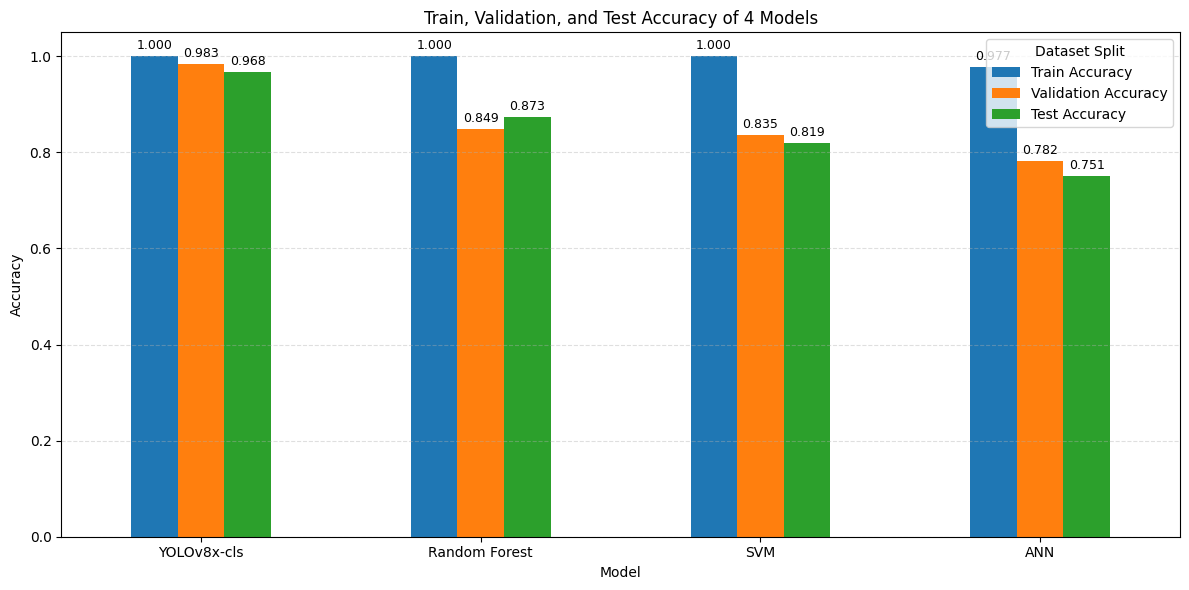

Saved bar graph: /kaggle/working/output/accuracy_graphs/train_val_test_accuracy_4_models_bar.png


In [29]:
plot_df = accuracy_df.set_index("Model")

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    rot=0
)

plt.title("Train, Validation, and Test Accuracy of 4 Models")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(title="Dataset Split")

# show values on bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

plt.tight_layout()

bar_graph_path = GRAPH_DIR / "train_val_test_accuracy_4_models_bar.png"
plt.savefig(bar_graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved bar graph:", bar_graph_path)

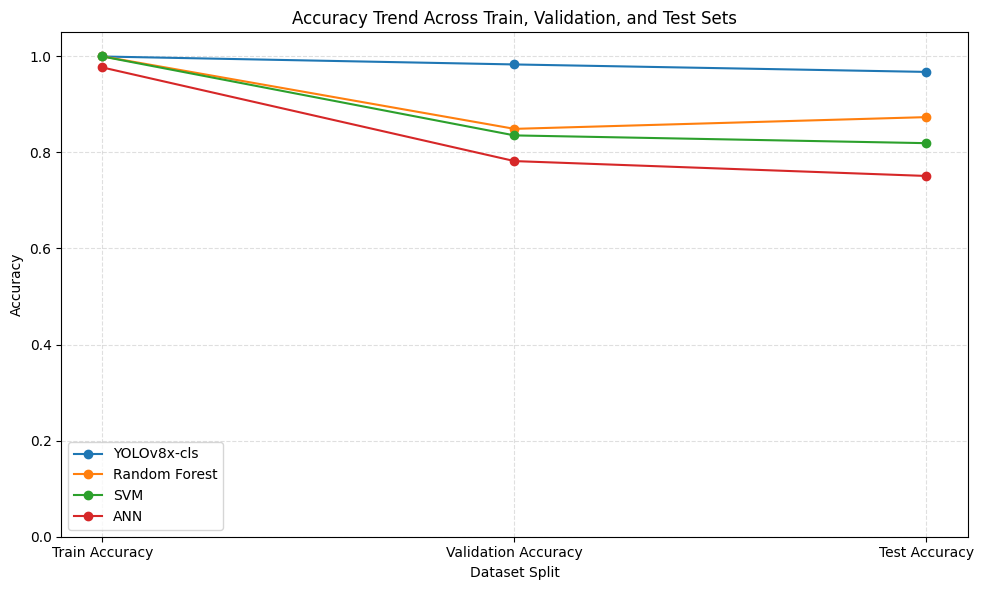

Saved line graph: /kaggle/working/output/accuracy_graphs/train_val_test_accuracy_4_models_line.png


In [30]:
line_df = accuracy_df.melt(
    id_vars="Model",
    value_vars=["Train Accuracy", "Validation Accuracy", "Test Accuracy"],
    var_name="Split",
    value_name="Accuracy"
)

plt.figure(figsize=(10, 6))

for model_name in accuracy_df["Model"]:
    temp = line_df[line_df["Model"] == model_name]
    plt.plot(temp["Split"], temp["Accuracy"], marker="o", label=model_name)

plt.title("Accuracy Trend Across Train, Validation, and Test Sets")
plt.xlabel("Dataset Split")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()

plt.tight_layout()

line_graph_path = GRAPH_DIR / "train_val_test_accuracy_4_models_line.png"
plt.savefig(line_graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved line graph:", line_graph_path)

In [32]:
from pathlib import Path
import zipfile
import os

WORKING_DIR = Path("/kaggle/working")
ZIP_PATH = WORKING_DIR / "all_outputs.zip"

# Delete old zip if exists
if ZIP_PATH.exists():
    ZIP_PATH.unlink()
    print("Old zip deleted:", ZIP_PATH)

skip_names = {
    ".virtual_documents",
    "all_outputs.zip"
}

with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    allowZip64=True
) as zf:
    
    for item in WORKING_DIR.rglob("*"):
        # skip folders/files inside skip_names
        if any(part in skip_names for part in item.parts):
            continue
        
        if item.is_file():
            arcname = item.relative_to(WORKING_DIR)
            zf.write(item, arcname)
            print("Added:", arcname)

print("\nZIP created successfully!")
print("ZIP path:", ZIP_PATH)
print("ZIP size MB:", ZIP_PATH.stat().st_size / (1024 * 1024))

Added: yolov8x-cls.pt
Added: yolo26n.pt
Added: output/rf_svm_ann_accuracy_results.txt
Added: output/model_accuracy_comparison.csv
Added: output/yolov8x_cls_best.pt
Added: output/rf_svm_ann_accuracy_results.csv
Added: runs/classify/val-2/val_batch2_labels.jpg
Added: runs/classify/val-2/confusion_matrix_normalized.png
Added: runs/classify/val-2/confusion_matrix.png
Added: runs/classify/val-2/val_batch0_labels.jpg
Added: runs/classify/val-2/val_batch0_pred.jpg
Added: runs/classify/val-2/val_batch2_pred.jpg
Added: runs/classify/val-2/val_batch1_labels.jpg
Added: runs/classify/val-2/val_batch1_pred.jpg
Added: runs/classify/val-4/val_batch2_labels.jpg
Added: runs/classify/val-4/confusion_matrix_normalized.png
Added: runs/classify/val-4/confusion_matrix.png
Added: runs/classify/val-4/val_batch0_labels.jpg
Added: runs/classify/val-4/val_batch0_pred.jpg
Added: runs/classify/val-4/val_batch2_pred.jpg
Added: runs/classify/val-4/val_batch1_labels.jpg
Added: runs/classify/val-4/val_batch1_pred.jpg
